# Task 2 — Cost Efficiency, Brand Channels & Measurement Plan

**Data source:** `data-cleaning/output/clean_daily.csv` only. Flags respected
(`flag_excluded` dropped; `flag_clicks_gt_impressions` out of any CTR use). All rates at
monthly grain or coarser.

**Standing caveats**
1. **Funnel-lag / attribution caveat.** SQO and Won are *fractional attributed credit* from a
   multi-touch model, and stages are not same-day cohorts. Every ratio here is a period-level
   ratio of attributed values — indicative, never a cohort conversion rate, never causal.
2. **`paid_brand_search` efficiency is confounded by demand harvesting** — it captures users
   already searching for the brand. Its low cost per SQO is never shown without this caveat;
   incrementality is untested in this data.
3. **`website` trends crossing 2023-11** carry the candidate-tracking-change annotation.
4. Spend↔outcome relationships are observational; channel mix, seasonality, and market
   conditions are unmodeled confounders.


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
import os

DECK = os.environ.get("DECK_FIGURES") == "1"   # deck variants: latte bg, no takeaway titles
FIG_DIR = REPO / "analysis" / "figures" / ("deck" if DECK else "")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(REPO / "data-cleaning" / "output" / "clean_daily.csv", parse_dates=["date"])
assert len(df) == 11926, "unexpected row count — rerun data-cleaning/clean.py"
d = df[~df["flag_excluded"]].copy()
d["ym"] = d["date"].dt.to_period("M")
d["yq"] = d["date"].dt.to_period("Q")

# cost geography: paid carries the bulk; event & regional also spend; the four
# brand/organic teams analyzed in 2.3 are verified zero-cost
ZERO_COST_TEAMS = ["content", "website", "social", "lifecycle"]
zc_cost = d.loc[d["team"].isin(ZERO_COST_TEAMS), "cost"].sum()
assert zc_cost == 0, "2.3 teams unexpectedly carry cost"
other_cost = d[~d["team"].isin(ZERO_COST_TEAMS + ["paid"])].groupby("team")["cost"].sum()
print(f"analysis rows: {len(d)} | zero-cost teams (2.3): {ZERO_COST_TEAMS}")
print(f"non-paid teams that DO carry cost: {(other_cost / 1e6).round(1).to_dict()} $M (event, regional)")


analysis rows: 10965 | zero-cost teams (2.3): ['content', 'website', 'social', 'lifecycle']
non-paid teams that DO carry cost: {'event': 9.5, 'regional': 4.3} $M (event, regional)


In [2]:
# ---- chart style (light mode; palette validated with dataviz validator) ----
INK, INK2, MUT = "#0b0b0b", "#52514e", "#898781"
GRID, BASE = "#e1e0d9", "#c3c2b7"
SURF = "#FFFBF4" if DECK else "#fcfcfb"        # deck variants sit on the latte slide bg
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": BASE, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUT, "ytick.color": MUT, "text.color": INK,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "ytick.left": False, "legend.frameon": False,
})

def footnote(fig, text, y=-0.02):
    if DECK:
        return                                  # slide-level footnotes replace these
    fig.text(0.01, y, text, fontsize=8.5, color=INK2, ha="left", va="top")

def takeaway_ax(ax, text, **kw):
    if not DECK:
        ax.set_title(text, **kw)                # slide title carries the takeaway in the deck

def takeaway_fig(fig, text, **kw):
    if not DECK:
        fig.suptitle(text, **kw)


## Rider A — SQO→Won decomposition (gates the deck headline)

Monthly SQO→Won ratio of *attributed* values (lag caveat: Won credited this month need not
come from this month's SQOs — the ratio is indicative, not a cohort rate). Then: is the FY25
improvement broad-based or concentrated? **Volume threshold: ≥ 100 attributed SQO in BOTH
fiscal years** (keeps 10 of 15 programs, 99.8% of SQO volume; below that, ratios swing on
single deals).


In [3]:
# monthly total ratio + per-program FY comparison
m_ratio = d.groupby("ym")[["sqo", "won"]].sum()
m_ratio["ratio_pct"] = m_ratio.won / m_ratio.sqo * 100

fyp = d.groupby(["program", "fiscal_year"])[["sqo", "won"]].sum().unstack()
fyp.columns = [f"{a}_{b}" for a, b in fyp.columns]
fyp["ratio_FY24"] = fyp.won_FY24 / fyp.sqo_FY24 * 100
fyp["ratio_FY25"] = fyp.won_FY25 / fyp.sqo_FY25 * 100
fyp["delta_pp"] = fyp.ratio_FY25 - fyp.ratio_FY24

VOL_MIN = 100
big = fyp[(fyp.sqo_FY24 >= VOL_MIN) & (fyp.sqo_FY25 >= VOL_MIN)].sort_values("sqo_FY25", ascending=False)
n_up = int((big.delta_pp > 0).sum())
tot = d.groupby("fiscal_year")[["sqo", "won"]].sum()
r24, r25 = tot.loc["FY24"].won / tot.loc["FY24"].sqo * 100, tot.loc["FY25"].won / tot.loc["FY25"].sqo * 100
print(f"TOTAL SQO->Won: FY24 {r24:.1f}% -> FY25 {r25:.1f}%  (+{r25 - r24:.1f}pp; rate factor x{r25 / r24:.3f})")
print(f"Won +71.3% decomposes as: SQO volume x1.355  *  SQO->Won rate x{r25 / r24:.3f}  = x1.713")
print(f"\nPrograms >= {VOL_MIN} SQO in both FYs: {len(big)}; improved: {n_up}")
print(big[["sqo_FY24", "sqo_FY25", "ratio_FY24", "ratio_FY25", "delta_pp"]].round(1).to_string())
print("\nCAVEAT - website ratio swing (-41pp) sits on the 2023-11 candidate tracking change and tiny SQO base.")


TOTAL SQO->Won: FY24 21.5% -> FY25 27.2%  (+5.7pp; rate factor x1.264)
Won +71.3% decomposes as: SQO volume x1.355  *  SQO->Won rate x1.264  = x1.713

Programs >= 100 SQO in both FYs: 10; improved: 8
                          sqo_FY24  sqo_FY25  ratio_FY24  ratio_FY25  delta_pp
program                                                                       
paid_brand_search           7213.4    9585.2        23.8        33.9      10.1
paid_search                 5521.7    8325.3        18.4        22.7       4.3
listicle_leadbuy_listing    1863.0    1985.9        15.3        17.1       1.8
content                     1198.9    1563.1        33.0        26.7      -6.3
paid_social                 1181.2    1467.5        10.9        19.4       8.5
prospect_email               588.2    1092.6        26.4        28.8       2.4
event                        647.8     651.4        17.9        18.5       0.6
regional                     605.4     519.0        19.9        25.0       5.1
website   

In [4]:
# within-program vs mix decomposition (share-weighted); paid_awareness dropped (0 SQO in FY24)
g = fyp[fyp.sqo_FY24 > 0]
s24, s25 = g.sqo_FY24 / g.sqo_FY24.sum(), g.sqo_FY25 / g.sqo_FY25.sum()
p24, p25 = g.won_FY24 / g.sqo_FY24, g.won_FY25 / g.sqo_FY25
within = float((s25 * (p25 - p24)).sum() * 100)
mix = float(((s25 - s24) * p24).sum() * 100)
contrib = (s25 * (p25 - p24)).sort_values(ascending=False) * 100
dw = g.won_FY25 - g.won_FY24
inc_share = (dw / dw.sum() * 100).sort_values(ascending=False)
print(f"decomposition of the +{r25 - r24:.1f}pp: within-program {within:+.1f}pp, mix {mix:+.1f}pp")
print("\ntop within-program contributions (pp):")
print(contrib.head(4).round(2).to_string())
print("\nshare of incremental Won (%):")
print(inc_share.head(4).round(1).to_string())


decomposition of the +5.7pp: within-program +5.0pp, mix +0.7pp

top within-program contributions (pp):
program
paid_brand_search           3.70
paid_search                 1.36
paid_social                 0.48
listicle_leadbuy_listing    0.14

share of incremental Won (%):
program
paid_brand_search    51.8
paid_search          29.5
prospect_email        5.4
paid_social           5.3


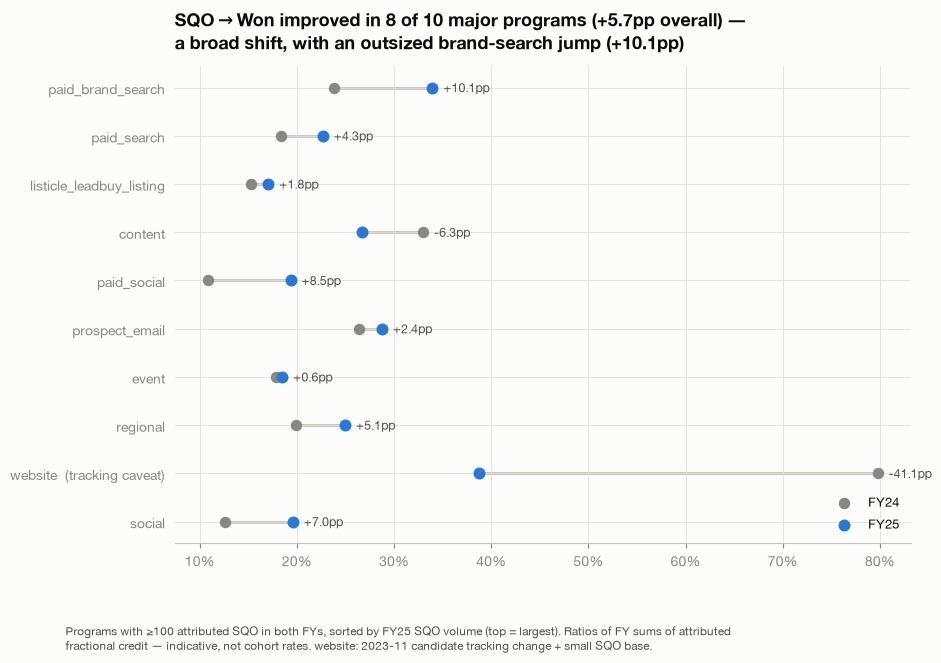

In [5]:
# ---- Figure 7: per-program SQO->Won dumbbell, FY24 -> FY25 ----
plot = big.sort_values("sqo_FY25")           # smallest at bottom -> largest on top
fig, ax = plt.subplots(figsize=(9.5, 6.2))
y = np.arange(len(plot))
for i, (prog, row) in enumerate(plot.iterrows()):
    ax.plot([row.ratio_FY24, row.ratio_FY25], [i, i], color=BASE, lw=2, zorder=1)
    ax.scatter(row.ratio_FY24, i, s=52, color=MUT, zorder=2)
    ax.scatter(row.ratio_FY25, i, s=58, color=C_BLUE, zorder=3)
    ax.annotate(f"{row.delta_pp:+.1f}pp", xy=(max(row.ratio_FY24, row.ratio_FY25), i),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
labels = [p + ("  (tracking caveat)" if p == "website" else "") for p in plot.index]
ax.set_yticks(y, labels, fontsize=10)
ax.tick_params(left=False)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}%"))
ax.scatter([], [], s=52, color=MUT, label="FY24")
ax.scatter([], [], s=58, color=C_BLUE, label="FY25")
ax.legend(loc="lower right", fontsize=9.5)
takeaway_ax(ax, "SQO$\\rightarrow$Won improved in 8 of 10 major programs (+5.7pp overall) —\n"
             "a broad shift, with an outsized brand-search jump (+10.1pp)",
             fontsize=13, fontweight="bold", pad=12)
footnote(fig, "Programs with ≥100 attributed SQO in both FYs, sorted by FY25 SQO volume (top = largest). "
              "Ratios of FY sums of attributed\nfractional credit — indicative, not cohort rates. "
              "website: 2023-11 candidate tracking change + small SQO base.")
fig.savefig(FIG_DIR / "fig7_sqo_won_decomposition.png")
plt.show()


### Rider A verdict

**Broad-based direction, concentrated magnitude — closer to the "broad-based" branch.**
Evidence: 8 of 10 meaningful-volume programs improved (direction consistent with a
sales-side or attribution-model change affecting everything at once), but the size of the
overall +5.7pp is dominated by paid_brand_search (+3.7pp of the +5.0pp within-program
effect; mix adds only +0.7pp), and brand+paid search take 81% of incremental Won credit.
**Deck guidance:** lead with SQO +35% as the marketing-driven number; present Won +71% as
SQO volume ×1.355 × SQO→Won rate ×1.264, with the rate component flagged as *candidate
sales-side / attribution-model change, cause not determinable from this data* — and note
the rate jump is largest in brand_search, which compounds its harvesting ambiguity.


## 2.1 Paid deep-dive: `paid_search` and `paid_social`

**Why these two:** the largest **non-branded** paid budgets (FY25: $88.3M and $39.4M) and a
clean capture-vs-awareness contrast. `paid_brand_search` is analyzed separately in 2.2
because its efficiency reading is confounded by demand harvesting. `listicle_leadbuy_listing`
appears in the 2.5 ranking but is a structurally different lead-buy;
`abm`/`paid_sponsorship`/`paid_awareness` are not SQO-scale lead-gen programs
(≤52 attributed SQO/FY each).

*All unit costs are cost per **attributed** demo/SQO/Won (period ratios, lag caveat).*


In [6]:
CH2 = ["paid_search", "paid_social"]
mm = d[d.program.isin(CH2 + ["paid_brand_search"])].groupby(["program", "ym"])[
    ["cost", "impressions", "clicks", "demo", "sqo", "won"]].sum()
for c in ["demo", "sqo", "won"]:
    mm[f"cost_per_{c}"] = mm.cost / mm[c]

fyc = d[d.program.isin(CH2 + ["paid_brand_search", "listicle_leadbuy_listing"])].groupby(
    ["program", "fiscal_year"])[["cost", "impressions", "demo", "sqo", "won"]].sum()
for c in ["demo", "sqo", "won"]:
    fyc[f"cost_per_{c}"] = fyc.cost / fyc[c]
print("FY unit costs (cost per attributed stage, $):")
print(fyc[["cost", "cost_per_demo", "cost_per_sqo", "cost_per_won"]].round(0).to_string())


FY unit costs (cost per attributed stage, $):
                                            cost  cost_per_demo  cost_per_sqo  cost_per_won
program                  fiscal_year                                                       
listicle_leadbuy_listing FY24         14160129.0         2665.0        7601.0       49772.0
                         FY25         13569460.0         2710.0        6833.0       40052.0
paid_brand_search        FY24         23702049.0         1753.0        3286.0       13779.0
                         FY25         69133894.0         4136.0        7213.0       21250.0
paid_search              FY24         48597688.0         3272.0        8801.0       47856.0
                         FY25         88327032.0         4129.0       10609.0       46801.0
paid_social              FY24         42220400.0         9265.0       35744.0      328819.0
                         FY25         39367475.0         9252.0       26826.0      138618.0


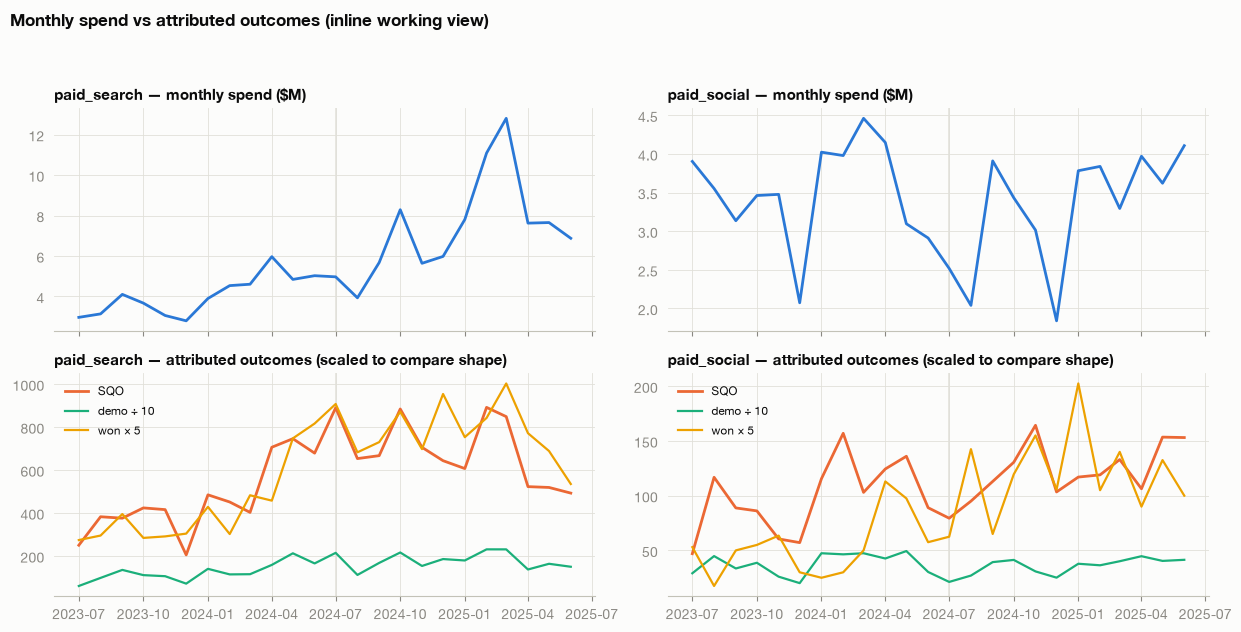

In [7]:
# monthly cost vs outcomes, inline view (not exported): spend and attributed outcomes per channel
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.4), sharex=True)
for j, prog in enumerate(CH2):
    s = mm.loc[prog]
    x = s.index.to_timestamp()
    axes[0, j].plot(x, s.cost / 1e6, color=C_BLUE, lw=2)
    axes[0, j].set_title(f"{prog} — monthly spend ($M)", fontsize=10.5, fontweight="bold")
    axes[1, j].plot(x, s.sqo, color=C_ORANGE, lw=2, label="SQO")
    axes[1, j].plot(x, s.demo / 10, color=C_AQUA, lw=1.6, label="demo ÷ 10")
    axes[1, j].plot(x, s.won * 5, color=C_YELLOW, lw=1.6, label="won × 5")
    axes[1, j].set_title(f"{prog} — attributed outcomes (scaled to compare shape)", fontsize=10.5, fontweight="bold")
    axes[1, j].legend(fontsize=8.5)
for ax in axes.ravel():
    ax.axvline(pd.Timestamp("2024-07-01"), color=GRID, lw=1.1, zorder=0)
fig.suptitle("Monthly spend vs attributed outcomes (inline working view)", fontsize=12, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


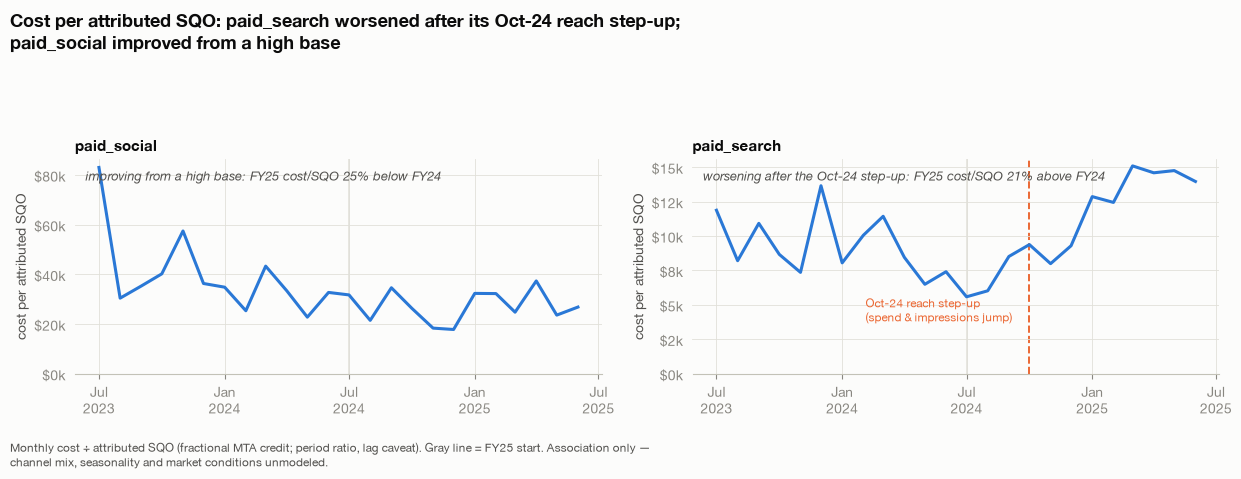

In [8]:
# ---- Figure 8: cost per attributed SQO over time, with the paid_search step-up annotated ----
STEP = pd.Timestamp("2024-10-01")   # observed step-up month (cost $5.7M Sep -> $8.3M Oct; brief said 2024-09 — data shows Oct)
# panel order: top-of-funnel channel (paid_social) on the LEFT
PANELS = [
    ("paid_social", "improving from a high base: FY25 cost/SQO 25% below FY24"),
    ("paid_search", "worsening after the Oct-24 step-up: FY25 cost/SQO 21% above FY24"),
]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True)
for ax, (prog, takeaway) in zip(axes, PANELS):
    s = mm.loc[prog, "cost_per_sqo"] / 1000
    ax.plot(s.index.to_timestamp(), s.values, color=C_BLUE, lw=2.2)
    ax.axvline(pd.Timestamp("2024-07-01"), color=GRID, lw=1.1, zorder=0)
    ax.set_title(prog, fontsize=11, fontweight="bold")
    ax.set_ylabel("cost per attributed SQO")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:.0f}k"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.set_ylim(bottom=0)
    ax.text(0.02, 0.96, takeaway, transform=ax.transAxes, va="top",
            fontsize=9.5, color=INK2, fontstyle="italic")
axes[1].axvline(STEP, color=C_ORANGE, lw=1.4, ls="--", zorder=1)
axes[1].annotate("Oct-24 reach step-up\n(spend & impressions jump)", xy=(STEP, 4), xytext=(-118, -2),
                 textcoords="offset points", fontsize=8.5, color=C_ORANGE)
takeaway_fig(fig, "Cost per attributed SQO: paid_search worsened after its Oct-24 reach step-up;\n"
             "paid_social improved from a high base", fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.02, 1, 0.86))
footnote(fig, "Monthly cost ÷ attributed SQO (fractional MTA credit; period ratio, lag caveat). "
              "Gray line = FY25 start. Association only —\nchannel mix, seasonality and market conditions unmodeled.", y=0.0)
fig.savefig(FIG_DIR / "fig8_cost_per_sqo_trends.png")
plt.show()


In [9]:
# paid_search step-up: before/after (hypothesis framing, not causal)
ps = mm.loc["paid_search"]
before = ps.loc["2023-10":"2024-09"]      # 12 months pre step-up
after = ps.loc["2024-10":"2025-06"]       # 9 months post
rows = {}
for name, w in [("before (Oct23-Sep24)", before), ("after (Oct24-Jun25)", after)]:
    rows[name] = dict(cost_M=w.cost.mean() / 1e6, impressions_M=w.impressions.mean() / 1e6,
                      sqo=w.sqo.mean(), cost_per_sqo=w.cost.sum() / w.sqo.sum())
ba = pd.DataFrame(rows).T
marginal = (after.cost.mean() - before.cost.mean()) / (after.sqo.mean() - before.sqo.mean())
print("paid_search monthly means, before vs after the observed Oct-24 step-up:")
print(ba.round(1).to_string())
print(f"\nimpressions x{after.impressions.mean() / before.impressions.mean():.1f}, "
      f"spend x{after.cost.mean() / before.cost.mean():.1f}, attributed SQO x{after.sqo.mean() / before.sqo.mean():.2f}")
print(f"marginal cost per incremental attributed SQO: ${marginal:,.0f} "
      f"vs ${rows['before (Oct23-Sep24)']['cost_per_sqo']:,.0f} average before "
      f"(x{marginal / rows['before (Oct23-Sep24)']['cost_per_sqo']:.1f})")
print("\nHYPOTHESIS: the marginal impressions bought after Oct-24 convert far below the historical average")
print("(consistent with Phase 1: CTR halved, click->demo held). NOT causal - budget timing, auction")
print("conditions, and seasonality are unmodeled. Confirming evidence: query/placement mix report,")
print("or a pre-registered budget A/B on the expanded inventory.")


paid_search monthly means, before vs after the observed Oct-24 step-up:
                      cost_M  impressions_M    sqo  cost_per_sqo
before (Oct23-Sep24)     4.4           12.6  560.3        7877.8
after (Oct24-Jun25)      8.2           32.3  679.4       12060.6

impressions x2.6, spend x1.9, attributed SQO x1.21
marginal cost per incremental attributed SQO: $31,734 vs $7,878 average before (x4.0)

HYPOTHESIS: the marginal impressions bought after Oct-24 convert far below the historical average
(consistent with Phase 1: CTR halved, click->demo held). NOT causal - budget timing, auction
conditions, and seasonality are unmodeled. Confirming evidence: query/placement mix report,
or a pre-registered budget A/B on the expanded inventory.


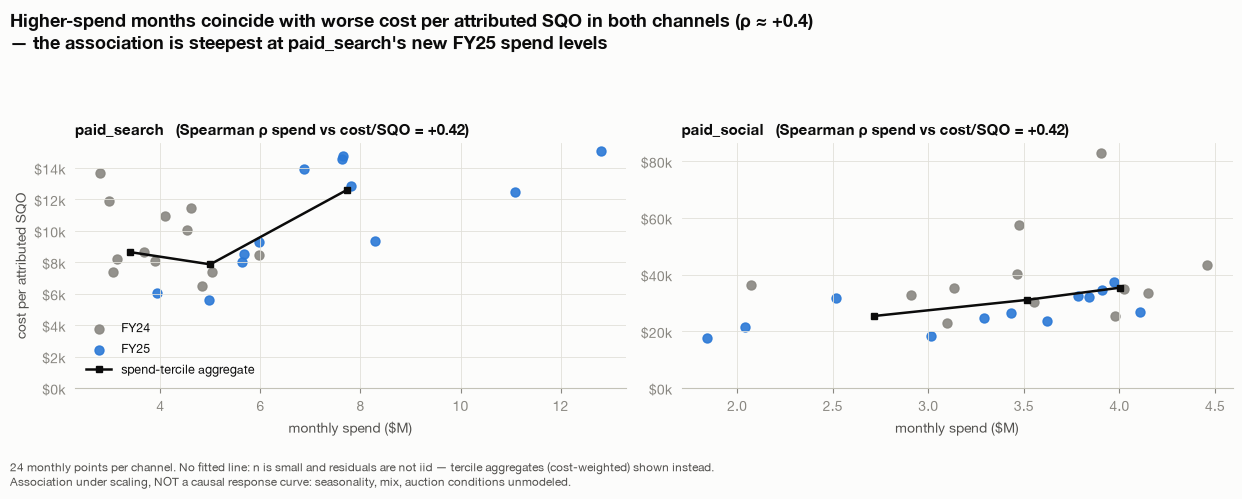

In [10]:
# ---- Figure 9: diminishing-returns view — monthly spend vs cost per attributed SQO ----
def spearman(x, y):
    rx, ry = pd.Series(x).rank(), pd.Series(y).rank()
    return np.corrcoef(rx, ry)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, prog in zip(axes, CH2):
    s = mm.loc[prog].reset_index()
    s["fy"] = np.where(s.ym.dt.to_timestamp() < "2024-07-01", "FY24", "FY25")
    for fy, color in [("FY24", MUT), ("FY25", C_BLUE)]:
        w = s[s.fy == fy]
        ax.scatter(w.cost / 1e6, w.cost_per_sqo / 1000, s=42, color=color, label=fy, alpha=0.9)
    # binned view (spend terciles) — honest alternative to a fitted line on 24 noisy points
    s["bin"] = pd.qcut(s.cost, 3, labels=["low", "mid", "high"])
    b = s.groupby("bin", observed=True).apply(
        lambda w: pd.Series({"x": w.cost.median() / 1e6, "y": w.cost.sum() / w.sqo.sum() / 1000}))
    ax.plot(b.x, b.y, color=INK, lw=1.8, marker="s", ms=5, label="spend-tercile aggregate")
    rho = spearman(s.cost, s.cost_per_sqo)
    ax.set_title(f"{prog}   (Spearman ρ spend vs cost/SQO = {rho:+.2f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("monthly spend ($M)")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:.0f}k"))
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("cost per attributed SQO")
axes[0].legend(fontsize=9)
takeaway_fig(fig, "Higher-spend months coincide with worse cost per attributed SQO in both channels (ρ ≈ +0.4)\n"
             "— the association is steepest at paid_search's new FY25 spend levels",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
footnote(fig, "24 monthly points per channel. No fitted line: n is small and residuals are not iid — tercile aggregates "
              "(cost-weighted) shown instead.\nAssociation under scaling, NOT a causal response curve: seasonality, "
              "mix, auction conditions unmodeled.", y=0.0)
fig.savefig(FIG_DIR / "fig9_diminishing_returns.png")
plt.show()


## 2.2 `paid_brand_search` — the confounded hero

Cheapest cost per attributed SQO in both years and the biggest SQO→Won improver — **and**
the one channel whose numbers cannot be taken at face value: branded search captures users
who already decided to look for the brand, so part of its attributed credit is demand
created elsewhere (or by brand strength itself). The caveat is printed **inside** every
figure of this section. The saturation trajectory below is the deck's Act 2 exhibit.


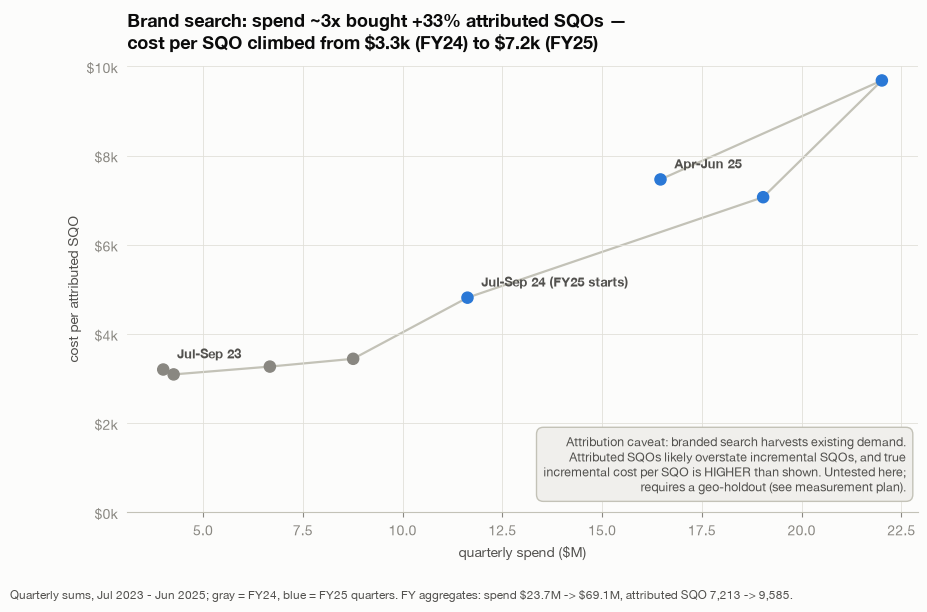

FY24: spend $23.7M, SQO 7,213, cost/SQO $3,286
FY25: spend $69.1M (x2.9), SQO 9,585 (+33%), cost/SQO $7,213 (x2.2)


In [11]:
# ---- Figure 10 (Act 2 exhibit): quarterly spend vs cost per attributed SQO trajectory ----
bq = d[d.program == "paid_brand_search"].groupby("yq")[["cost", "sqo"]].sum()
bq["cps"] = bq.cost / bq.sqo
bfy = fyc.loc["paid_brand_search"]

fig, ax = plt.subplots(figsize=(10.2, 5.8))
x, y = bq.cost.values / 1e6, bq.cps.values / 1000
colors = [MUT if q < pd.Period("2024Q3") else C_BLUE for q in bq.index]
ax.plot(x, y, color=BASE, lw=1.6, zorder=1)
ax.scatter(x, y, s=64, c=colors, zorder=2)
for q, xi, yi in zip(bq.index, x, y):
    if q in (bq.index[0], bq.index[-1], pd.Period("2024Q3")):
        lbl = {bq.index[0]: "Jul-Sep 23", pd.Period("2024Q3"): "Jul-Sep 24 (FY25 starts)",
               bq.index[-1]: "Apr-Jun 25"}[q]
        ax.annotate(lbl, xy=(xi, yi), xytext=(10, 8), textcoords="offset points",
                    fontsize=9, color=INK2, fontweight="bold")
ax.set_xlabel("quarterly spend ($M)")
ax.set_ylabel("cost per attributed SQO")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:.0f}k"))
ax.set_ylim(bottom=0)
takeaway_ax(ax, "Brand search: spend ~3x bought +33% attributed SQOs —\n"
             "cost per SQO climbed from \\$3.3k (FY24) to \\$7.2k (FY25)",
             fontsize=13, fontweight="bold", pad=12)
ax.text(0.985, 0.04,
        "Attribution caveat: branded search harvests existing demand.\n"
        "Attributed SQOs likely overstate incremental SQOs, and true\n"
        "incremental cost per SQO is HIGHER than shown. Untested here;\n"
        "requires a geo-holdout (see measurement plan).",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color=INK2,
        bbox=dict(boxstyle="round,pad=0.55", facecolor="#f0efec", edgecolor=BASE))
footnote(fig, "Quarterly sums, Jul 2023 - Jun 2025; gray = FY24, blue = FY25 quarters. "
              "FY aggregates: spend \\$23.7M -> \\$69.1M, attributed SQO 7,213 -> 9,585.")
fig.savefig(FIG_DIR / "fig10_brand_search_saturation.png")
plt.show()

print(f"FY24: spend ${bfy.loc['FY24','cost']/1e6:.1f}M, SQO {bfy.loc['FY24','sqo']:,.0f}, cost/SQO ${bfy.loc['FY24','cost_per_sqo']:,.0f}")
print(f"FY25: spend ${bfy.loc['FY25','cost']/1e6:.1f}M (x{bfy.loc['FY25','cost']/bfy.loc['FY24','cost']:.1f}), "
      f"SQO {bfy.loc['FY25','sqo']:,.0f} (+{(bfy.loc['FY25','sqo']/bfy.loc['FY24','sqo']-1)*100:.0f}%), "
      f"cost/SQO ${bfy.loc['FY25','cost_per_sqo']:,.0f} (x{bfy.loc['FY25','cost_per_sqo']/bfy.loc['FY24','cost_per_sqo']:.1f})")


## 2.3 Brand / organic channels: content, website, social, lifecycle

These four teams carry **zero attributed media cost** (asserted at load; `event` and
`regional` are not in this group — they spend $9.5M / $4.3M over the period and are noted
in 2.5). Their attributed demo/SQO is what the MTA model credits them — and if they create demand
that people later express as branded searches, **their contribution is understated and
brand_search's overstated**. That asymmetry is the bridge to the measurement plan: only
incrementality testing can price it.

`website` demo crossing 2023-11 carries the candidate-tracking-change annotation; its demo
trend is not interpretable across that date. Secondary finding: **lifecycle SQO +114% YoY**
(682.7 → 1,463.7 attributed SQO — small base vs paid's 21,438).


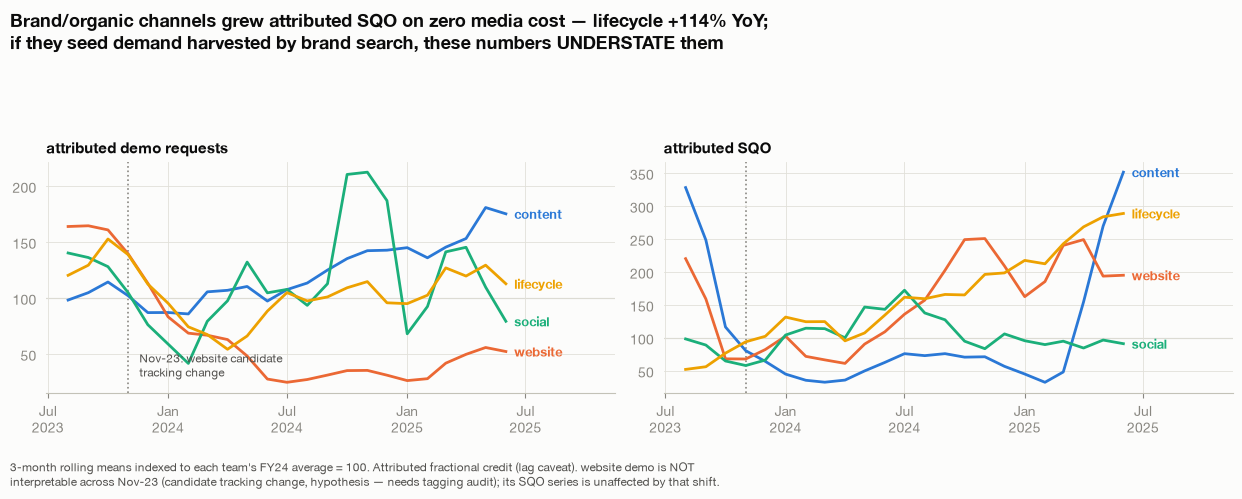

brand/organic FY totals (attributed):
                       demo     sqo    won
team      fiscal_year                     
content   FY24         4364  1277.8  418.4
          FY25         6505  1666.7  455.7
lifecycle FY24         3114   682.7  206.8
          FY25         3418  1463.7  479.0
social    FY24          390   119.5   15.0
          FY25          512   121.5   23.8
website   FY24         8089   156.6  124.9
          FY25         3402   317.9  123.0


In [12]:
# ---- Figure 11: brand/organic attributed SQO trends (indexed, 3-mo rolling) ----
TEAMS = [("content", C_BLUE), ("website", C_ORANGE), ("social", C_AQUA), ("lifecycle", C_YELLOW)]
tt = d[d.team.isin([t for t, _ in TEAMS])].groupby(["team", "ym"])[["demo", "sqo"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharex=True)
for ax, metric, label in [(axes[0], "demo", "attributed demo requests"), (axes[1], "sqo", "attributed SQO")]:
    for team, color in TEAMS:
        s = tt.loc[team, metric].rolling(3, min_periods=2).mean()
        base = s.loc["2023-07":"2024-06"].mean()          # FY24 average = 100
        sidx = s / base * 100
        ax.plot(sidx.index.to_timestamp(), sidx.values, color=color, lw=2)
        ax.annotate(team, xy=(sidx.index[-1].to_timestamp(), sidx.iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=9.5, fontweight="bold", color=color)
    ax.axhline(100, color=BASE, lw=0.8, zorder=0)
    ax.axvline(pd.Timestamp("2023-11-01"), color=MUT, lw=1.2, ls=":", zorder=1)
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.set_xlim(right=pd.Timestamp("2025-11-15"))
axes[0].annotate("Nov-23: website candidate\ntracking change", xy=(pd.Timestamp("2023-11-01"), 30),
                 xytext=(8, 0), textcoords="offset points", fontsize=8.5, color=INK2)
takeaway_fig(fig, "Brand/organic channels grew attributed SQO on zero media cost — lifecycle +114% YoY;\n"
             "if they seed demand harvested by brand search, these numbers UNDERSTATE them",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.02, 1, 0.86))
footnote(fig, "3-month rolling means indexed to each team's FY24 average = 100. Attributed fractional credit "
              "(lag caveat). website demo is NOT\ninterpretable across Nov-23 (candidate tracking change, "
              "hypothesis — needs tagging audit); its SQO series is unaffected by that shift.", y=0.0)
fig.savefig(FIG_DIR / "fig11_brand_organic_trends.png")
plt.show()

team_fy = d[d.team.isin([t for t, _ in TEAMS])].groupby(["team", "fiscal_year"])[["demo", "sqo", "won"]].sum()
print("brand/organic FY totals (attributed):")
print(team_fy.round(1).to_string())


## 2.4 Measurement plan — skeleton (structure only; prose to be written by author)

**a) Geo-holdout on `paid_brand_search`**
- Unit: geo markets (country or metro tier, depending on spend granularity available)
- Design: withhold branded search in a matched share of geos (holdout share TBD, e.g.
  10–20% of spend-weighted geos); readout via matched-market or synthetic-control
  comparison (CausalImpact-style) of holdout vs synthetic counterfactual
- Duration: placeholder [6–10 weeks + cooldown; power calc from geo-level SQO variance]
- Primary metric: **total SQOs in geo (from CRM), NOT attributed SQOs** — attribution is
  the very thing under test; attributed metrics would mechanically favor the channel
- Guardrails: branded impression share / competitor coverage, CPCs in retained geos,
  demo-request SLA, revenue pacing in holdout geos
- Decision rule: placeholder [if incremental cost per SQO in holdout test > $X vs $7.2k
  attributed, cap/reallocate; else scale with periodic re-tests]

**b) Brand-budget-increase measurement (awareness investment)**
- Same skeleton: geo-split increase, matched-market/synthetic-control readout, duration
  placeholder [8–12 weeks; brand effects are slower]
- Primary metric: total SQOs in geo (lagged window)
- Leading indicators: branded search query volume, direct traffic, unattributed/self-reported
  demo requests, branded CTR drift
- Guardrails: paid efficiency in test geos, share-of-voice tracking

**c) MMM as the ongoing allocation layer**
- Adds over MTA: cross-channel effects, adstock & saturation curves, works without
  user-level tracking (privacy-robust), captures offline/unclickable media
- Needs: 2+ years of history (**exists: 24 months**), weekly-or-monthly spend/outcome grain
  per channel (exists), holdout validation, and the experiment results from (a)/(b) as
  calibration priors
- Honest limits: wide intervals with ~7 active spend channels, model-dependence
  (priors/curve shapes), cannot rescue a mis-specified channel taxonomy
- Positioning: experiments calibrate MMM; MMM generalizes between experiments — they are
  complements, not rivals


## 2.5 Budget reallocation candidates

### What the data shows (numbers = FY sums of attributed credit)

1. **Cost per attributed SQO, FY25 (level):** listicle $6,833 < brand_search $7,213 <
   paid_search $10,609 < paid_social $26,826. **Trend FY24→FY25:** brand_search ×2.2
   (worsening), paid_search +21% (worsening), paid_social −25% (improving), listicle −10%
   (improving). Note: the FY25 cost-per-SQO leader is the lead-buy (`listicle`), a
   structurally different channel whose lead quality this data cannot assess.
2. **Cost per attributed Won, FY25:** brand_search $21,250 < listicle $40,052 <
   paid_search $46,801 < paid_social $138,618 (halved from $328,819).
3. **paid_search marginal economics after the Oct-24 step-up:** monthly spend +$3.8M
   (×1.9), impressions ×2.6, attributed SQO ×1.21 — marginal cost per incremental
   attributed SQO ≈ $31.7k, ~4× the pre-period average $7.9k. *(Before/after monthly
   means; association, not causal.)*
4. **brand_search saturation trajectory:** spend ×2.9, SQO +33%, cost/SQO $3,286→$7,213
   (fig10). ⚠ incrementality untested; attributed cost/SQO likely understates true
   incremental cost/SQO.
5. **SQO→Won (Rider A):** total 21.5%→27.2%; broad-based direction (8/10 programs up),
   magnitude concentrated in brand_search (+3.7pp of +5.7pp).
6. **Zero-cost channels:** content/website/social/lifecycle produce 13.6% of FY25
   attributed SQO on $0 media; lifecycle SQO +114% YoY (small base). Separately,
   `regional` and `event` DO spend ($4.3M / $9.5M full period) at full-period cost per
   attributed SQO of ~$3.8k / ~$7.3k — competitive levels, but both cut spend in FY25;
   volumes are small and the same attribution caveats apply.

### Recommendation candidates (hypotheses for the author to refine)

| candidate | confidence | reason for confidence level |
|---|---|---|
| Cap `paid_brand_search` at ~current spend; run the geo-holdout before any increase | **high** | saturation visible in attributed data alone; harvesting risk only strengthens the cap case; action is reversible |
| Re-examine `paid_search`'s post-Oct-24 expanded inventory (query/placement audit; consider rolling back the lowest-quality reach) | **medium** | marginal-cost signal is strong but before/after is confounded by seasonality & auction shifts |
| Protect (do not cut) `paid_social` while testing its assist role via brand-lift/holdout | **medium** | efficiency improving (cost/won −58%) but volumes small and its value is mostly upper-funnel, which MTA under-credits |
| Fund `lifecycle` expansion experiments | **low-medium** | +114% SQO YoY but small base; zero-cost channels' attributed credit is noisy |
| Do not use attributed cost-per-SQO alone to shift budget between branded and non-branded search | **high** (as a rule) | the two channels' attribution biases point in opposite directions; only (a)/(b) experiments can price the gap |


In [13]:
# ---- verification: every number cited above re-derived; hard-fails on drift ----
def close(a, b, tol=0.01):
    return abs(a - b) <= tol * max(1.0, abs(b))

assert close(r24, 21.5, 0.005) and close(r25, 27.2, 0.005)
assert close(r25 / r24, 1.264, 0.002)
assert len(big) == 10 and n_up == 8
assert close(within, 5.0, 0.02) and close(mix, 0.7, 0.06)
assert close(contrib.loc["paid_brand_search"], 3.7, 0.02)
assert close(big.loc["paid_brand_search", "delta_pp"], 10.1, 0.005)
assert close(inc_share.loc["paid_brand_search"] + inc_share.loc["paid_search"], 81.3, 0.01)
v = fyc.loc[("paid_brand_search", "FY24")]; assert close(v.cost / 1e6, 23.7, 0.005) and close(v.cost_per_sqo, 3286, 0.005)
v = fyc.loc[("paid_brand_search", "FY25")]; assert close(v.cost / 1e6, 69.1, 0.005) and close(v.cost_per_sqo, 7213, 0.005)
assert close(fyc.loc[("paid_search", "FY25"), "cost_per_sqo"], 10609, 0.005)
assert close(fyc.loc[("paid_search", "FY24"), "cost_per_sqo"], 8801, 0.005)
assert close(fyc.loc[("paid_social", "FY25"), "cost_per_sqo"], 26826, 0.005)
assert close(fyc.loc[("paid_social", "FY24"), "cost_per_sqo"], 35744, 0.005)
assert close(fyc.loc[("paid_social", "FY25"), "cost_per_won"], 138618, 0.005)
assert close(fyc.loc[("paid_social", "FY24"), "cost_per_won"], 328819, 0.005)
assert close(fyc.loc[("paid_search", "FY25"), "cost_per_won"], 46801, 0.005)
assert close(fyc.loc[("paid_brand_search", "FY25"), "cost_per_won"], 21250, 0.005)
assert close(fyc.loc[("listicle_leadbuy_listing", "FY25"), "cost_per_sqo"], 6833, 0.005)
assert close(fyc.loc[("listicle_leadbuy_listing", "FY24"), "cost_per_sqo"], 7601, 0.005)
assert close(fyc.loc[("listicle_leadbuy_listing", "FY25"), "cost_per_won"], 40052, 0.005)
assert close(marginal, 31734, 0.005)
assert close(after.impressions.mean() / before.impressions.mean(), 2.56, 0.005)
assert close(after.cost.mean() / before.cost.mean(), 1.86, 0.005)
assert close(after.sqo.mean() / before.sqo.mean(), 1.21, 0.005)
assert close(before.cost.sum() / before.sqo.sum(), 7878, 0.005)
lf = team_fy.loc["lifecycle"]
assert close((lf.loc["FY25", "sqo"] / lf.loc["FY24", "sqo"] - 1) * 100, 114.4, 0.005)
f25 = d[d.fiscal_year == "FY25"]
zc_share = f25[f25.team.isin(ZERO_COST_TEAMS)].sqo.sum() / f25.sqo.sum() * 100
assert close(zc_share, 13.6, 0.01)
ev_re = d.groupby("team")[["cost", "sqo"]].sum()
assert close(ev_re.loc["event", "cost"] / 1e6, 9.5, 0.01) and close(ev_re.loc["regional", "cost"] / 1e6, 4.3, 0.01)
assert close(ev_re.loc["regional", "cost"] / ev_re.loc["regional", "sqo"], 3832, 0.01)
assert close(ev_re.loc["event", "cost"] / ev_re.loc["event", "sqo"], 7287, 0.01)
print("All cited Task 2 numbers verified against the cleaned data. OK")
print(f"(zero-cost teams' share of FY25 attributed SQO: {zc_share:.1f}%)")


All cited Task 2 numbers verified against the cleaned data. OK
(zero-cost teams' share of FY25 attributed SQO: 13.6%)
